Class weights: {'cold': 0.649, 'cool': 1.269, 'hot': 2.275, 'warm': 0.811}

🔥 Accuracy (test): 90.45%

📊 Classification Report:
              precision    recall  f1-score   support

        cold       0.99      0.94      0.96       710
        cool       0.85      0.90      0.87       363
         hot       0.74      0.93      0.82       202
        warm       0.92      0.86      0.89       568

    accuracy                           0.90      1843
   macro avg       0.87      0.91      0.89      1843
weighted avg       0.91      0.90      0.91      1843



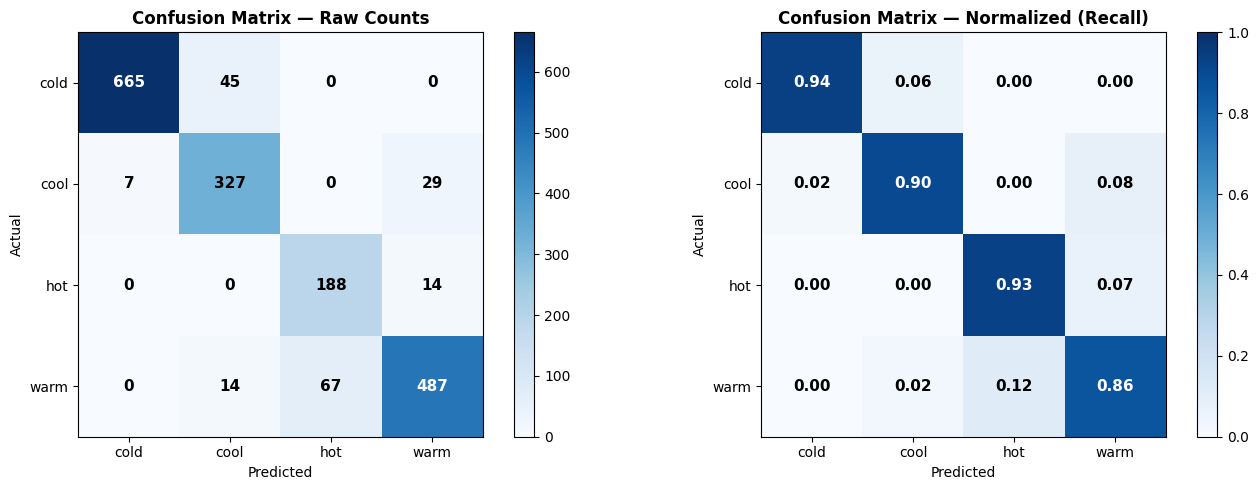

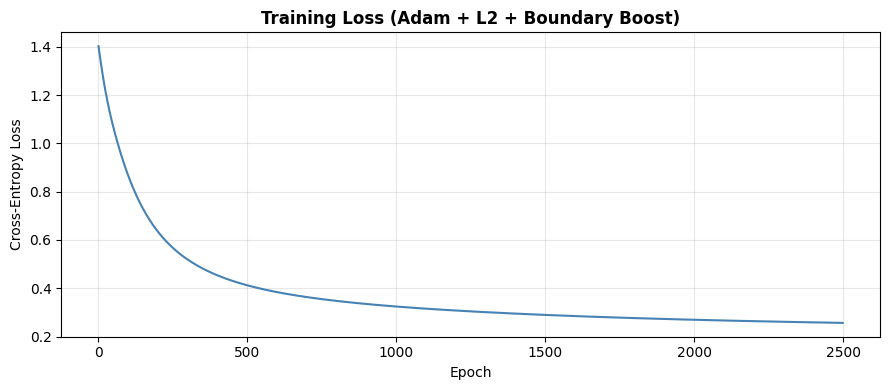


Label mapping: {'cold': 0, 'cool': 1, 'hot': 2, 'warm': 3}


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

# ===== LOAD =====
df = pd.read_csv("DATASET_BAITOAN2.csv")

# ===== FEATURE ENGINEERING =====
df['temp_squared']  = df['temperature'] ** 2
df['temp_cubed']    = df['temperature'] ** 3
df['temp_abs']      = np.abs(df['temperature'])
df['temp_x_delta']  = df['temperature'] * df['delta_temp']
df['temp_x_hour']   = df['temperature'] * df['local_hour_24']
df['delta_squared'] = df['delta_temp'] ** 2

# Bin phân loại thô
df['temp_bin_cold'] = (df['temperature'] < 10).astype(float)
df['temp_bin_cool'] = ((df['temperature'] >= 10) & (df['temperature'] < 22)).astype(float)
df['temp_bin_warm'] = ((df['temperature'] >= 22) & (df['temperature'] < 29)).astype(float)
df['temp_bin_hot']  = (df['temperature'] >= 29).astype(float)

# --- Boundary features: tập trung vào 2 vùng nhầm lẫn chính ---
# Vùng warm/hot: 26-32°C (warm→hot là lỗi lớn nhất)
df['dist_to_28']    = np.abs(df['temperature'] - 28)
df['dist_to_14']    = np.abs(df['temperature'] - 14)
df['in_wh_zone']    = ((df['temperature'] >= 26) & (df['temperature'] <= 32)).astype(float)
df['in_cc_zone']    = ((df['temperature'] >= 11) & (df['temperature'] <= 17)).astype(float)
df['delta_in_wh']   = df['delta_temp'] * df['in_wh_zone']   # xu hướng tại vùng warm/hot
df['delta_in_cc']   = df['delta_temp'] * df['in_cc_zone']   # xu hướng tại vùng cold/cool
df['hour_in_wh']    = df['hour_sin']  * df['in_wh_zone']    # thời điểm tại vùng warm/hot
df['hour_in_cc']    = df['hour_cos']  * df['in_cc_zone']
df['temp_delta_sq'] = df['temperature'] * df['delta_squared']

features = [
    'temperature', 'delta_temp', 'hour_sin', 'hour_cos',
    'temp_squared', 'temp_cubed', 'temp_abs',
    'temp_x_delta', 'temp_x_hour', 'delta_squared',
    'temp_bin_cold', 'temp_bin_cool', 'temp_bin_warm', 'temp_bin_hot',
    'dist_to_28', 'dist_to_14',
    'in_wh_zone', 'in_cc_zone',
    'delta_in_wh', 'delta_in_cc',
    'hour_in_wh', 'hour_in_cc',
    'temp_delta_sq',
]

X = df[features].values
scaler = StandardScaler()
X = scaler.fit_transform(X)

le = LabelEncoder()
y  = le.fit_transform(df['label'])
# cold=0, cool=1, hot=2, warm=3

class_weights = compute_class_weight('balanced', classes=np.unique(y), y=y)
print("Class weights:", dict(zip(le.classes_, class_weights.round(3))))

# ===== TRAIN/TEST SPLIT (giữ index để build sample weights) =====
idx = np.arange(len(y))
idx_train, idx_test, y_train, y_test = train_test_split(
    idx, y, test_size=0.2, random_state=42, stratify=y
)
X_train, X_test = X[idx_train], X[idx_test]

# ===== SAMPLE WEIGHTS: class weight + boost vùng biên =====
in_wh = df['in_wh_zone'].values
in_cc = df['in_cc_zone'].values
BOUNDARY_BOOST = 2.5   # samples trong vùng nhầm lẫn được học kỹ hơn 2.5x

sample_weights = class_weights[y_train].copy()
sample_weights[in_wh[idx_train] == 1] *= BOUNDARY_BOOST
sample_weights[in_cc[idx_train] == 1] *= BOUNDARY_BOOST

# ===== SOFTMAX =====
def softmax(z):
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

# ===== TRAIN: ADAM + L2 + SAMPLE WEIGHTS =====
def train(X, y, sample_weights, lr=0.001, epochs=2500, lam=0.001):
    n, f   = X.shape
    n_cls  = len(np.unique(y))
    oh     = np.zeros((n, n_cls)); oh[np.arange(n), y] = 1
    sw     = sample_weights / sample_weights.mean()
    W      = np.random.randn(f, n_cls) * 0.01
    b      = np.zeros((1, n_cls))
    mW = np.zeros_like(W); vW = np.zeros_like(W)
    mb = np.zeros_like(b); vb = np.zeros_like(b)
    b1, b2, eps = 0.9, 0.999, 1e-8
    losses = []
    for t in range(1, epochs + 1):
        p    = softmax(X @ W + b)
        diff = (p - oh) * sw[:, None]
        dW   = X.T @ diff / n + 2 * lam * W
        db   = diff.sum(0, keepdims=True) / n
        mW = b1*mW + (1-b1)*dW; vW = b2*vW + (1-b2)*dW**2
        mb = b1*mb + (1-b1)*db; vb = b2*vb + (1-b2)*db**2
        W -= lr * (mW/(1-b1**t)) / (np.sqrt(vW/(1-b2**t)) + eps)
        b -= lr * (mb/(1-b1**t)) / (np.sqrt(vb/(1-b2**t)) + eps)
        losses.append(-np.mean(np.sum(oh * np.log(p+1e-9), axis=1)))
    return W, b, losses

np.random.seed(42)
W, b, losses = train(X_train, y_train, sample_weights)

# ===== EVALUATE =====
y_pred = np.argmax(softmax(X_test @ W + b), axis=1)
acc = np.mean(y_pred == y_test)
print(f"\n🔥 Accuracy (test): {acc*100:.2f}%")
print("\n📊 Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# ===== CONFUSION MATRIX =====
cm      = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
n_cls   = len(le.classes_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title, fmt in zip(
    axes,
    [cm, cm_norm],
    ["Raw Counts", "Normalized (Recall)"],
    ["{:.0f}", "{:.2f}"]
):
    im = ax.imshow(data, cmap='Blues', vmin=0, vmax=(1 if 'Norm' in title else None))
    ax.set_title(f"Confusion Matrix — {title}", fontsize=12, fontweight='bold')
    ax.set_xticks(range(n_cls)); ax.set_xticklabels(le.classes_)
    ax.set_yticks(range(n_cls)); ax.set_yticklabels(le.classes_)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    plt.colorbar(im, ax=ax)
    for i in range(n_cls):
        for j in range(n_cls):
            v = data[i, j]
            c = "white" if v > (0.5 if 'Norm' in title else data.max()/2) else "black"
            ax.text(j, i, fmt.format(v), ha="center", va="center",
                    color=c, fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches='tight')
plt.show()

# ===== LOSS CURVE =====
plt.figure(figsize=(9, 4))
plt.plot(losses, color='steelblue', linewidth=1.5)
plt.title("Training Loss (Adam + L2 + Boundary Boost)", fontsize=12, fontweight='bold')
plt.xlabel("Epoch"); plt.ylabel("Cross-Entropy Loss")
plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("training_loss.png", dpi=150, bbox_inches='tight')
plt.show()

print("\nLabel mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

In [2]:
# ================================================================
# CELL DỰ ĐOÁN — dán sau cell huấn luyện, chạy riêng
# Yêu cầu: W, b, scaler, le, softmax đã có từ cell train
# ================================================================

def build_features(temperature, delta_temp, local_hour_24):
    h = local_hour_24 * (2 * np.pi / 24)
    row = {
        'temperature':   temperature,
        'delta_temp':    delta_temp,
        'hour_sin':      np.sin(h),
        'hour_cos':      np.cos(h),
        'temp_squared':  temperature ** 2,
        'temp_cubed':    temperature ** 3,
        'temp_abs':      abs(temperature),
        'temp_x_delta':  temperature * delta_temp,
        'temp_x_hour':   temperature * local_hour_24,
        'delta_squared': delta_temp ** 2,
        'temp_bin_cold': float(temperature < 10),
        'temp_bin_cool': float(10 <= temperature < 22),
        'temp_bin_warm': float(22 <= temperature < 29),
        'temp_bin_hot':  float(temperature >= 29),
        'dist_to_28':    abs(temperature - 28),
        'dist_to_14':    abs(temperature - 14),
        'in_wh_zone':    float(26 <= temperature <= 32),
        'in_cc_zone':    float(11 <= temperature <= 17),
        'delta_in_wh':   delta_temp * float(26 <= temperature <= 32),
        'delta_in_cc':   delta_temp * float(11 <= temperature <= 17),
        'hour_in_wh':    np.sin(h) * float(26 <= temperature <= 32),
        'hour_in_cc':    np.cos(h) * float(11 <= temperature <= 17),
        'temp_delta_sq': temperature * delta_temp ** 2,
    }
    feature_order = [
        'temperature', 'delta_temp', 'hour_sin', 'hour_cos',
        'temp_squared', 'temp_cubed', 'temp_abs',
        'temp_x_delta', 'temp_x_hour', 'delta_squared',
        'temp_bin_cold', 'temp_bin_cool', 'temp_bin_warm', 'temp_bin_hot',
        'dist_to_28', 'dist_to_14',
        'in_wh_zone', 'in_cc_zone',
        'delta_in_wh', 'delta_in_cc',
        'hour_in_wh', 'hour_in_cc',
        'temp_delta_sq',
    ]
    return np.array([[row[f] for f in feature_order]])


def predict(temperature, delta_temp, local_hour_24):
    """
    Du doan trang thai nhiet do tai t+1.
    Args:
        temperature    (float): Nhiet do hien tai (C)
        delta_temp     (float): Chenh lech nhiet do so voi gio truoc
        local_hour_24  (int)  : Gio trong ngay (0-23)
    Returns:
        str: Nhan du doan ('cold' | 'cool' | 'warm' | 'hot')
    """
    x    = scaler.transform(build_features(temperature, delta_temp, local_hour_24))
    prob = softmax(x @ W + b)[0]
    idx  = np.argmax(prob)

    print(f"\nDu doan trang thai nhiet do (t+1):")
    print(f"   Nhan      : {le.classes_[idx].upper()}")
    print(f"   Do tin cay: {prob[idx]*100:.1f}%")
    print(f"\n   Xac suat cac lop:")
    for i in np.argsort(prob)[::-1]:
        bar = 'X' * int(prob[i] * 20)
        print(f"   {le.classes_[i]:5s}  {prob[i]*100:5.1f}%  {bar}")

    return le.classes_[idx]


# ================================================================
# NHAP DU LIEU
# ================================================================
temperature   = float(input("Nhiet do hien tai (C)   : "))
delta_temp    = float(input("Delta nhiet do (t - t-1): "))
local_hour_24 =   int(input("Gio trong ngay (0-23)   : "))

ket_qua = predict(temperature, delta_temp, local_hour_24)


Du doan trang thai nhiet do (t+1):
   Nhan      : WARM
   Do tin cay: 91.4%

   Xac suat cac lop:
   warm    91.4%  XXXXXXXXXXXXXXXXXX
   cool     5.1%  X
   hot      3.3%  
   cold     0.2%  


In [3]:
predict(10, 0.1, 6)


Du doan trang thai nhiet do (t+1):
   Nhan      : COLD
   Do tin cay: 78.3%

   Xac suat cac lop:
   cold    78.3%  XXXXXXXXXXXXXXX
   cool    15.9%  XXX
   warm     5.7%  X
   hot      0.1%  


'cold'

In [4]:
predict(29, 0.2, 14)


Du doan trang thai nhiet do (t+1):
   Nhan      : HOT
   Do tin cay: 77.8%

   Xac suat cac lop:
   hot     77.8%  XXXXXXXXXXXXXXX
   warm    22.0%  XXXX
   cool     0.2%  
   cold     0.0%  


'hot'

In [5]:
predict(32, -3, 17)


Du doan trang thai nhiet do (t+1):
   Nhan      : HOT
   Do tin cay: 91.6%

   Xac suat cac lop:
   hot     91.6%  XXXXXXXXXXXXXXXXXX
   warm     8.3%  X
   cool     0.1%  
   cold     0.0%  


'hot'

In [6]:
predict(22, +2, 23)


Du doan trang thai nhiet do (t+1):
   Nhan      : WARM
   Do tin cay: 84.8%

   Xac suat cac lop:
   warm    84.8%  XXXXXXXXXXXXXXXX
   cool    14.4%  XX
   hot      0.6%  
   cold     0.2%  


'warm'

In [7]:
predict(8, +3, 5)


Du doan trang thai nhiet do (t+1):
   Nhan      : COLD
   Do tin cay: 98.9%

   Xac suat cac lop:
   cold    98.9%  XXXXXXXXXXXXXXXXXXX
   warm     1.0%  
   cool     0.1%  
   hot      0.0%  


'cold'

In [8]:
predict(25, 1, 14)
predict(25.1, 1, 14)
predict(25.2, 1, 14)


Du doan trang thai nhiet do (t+1):
   Nhan      : WARM
   Do tin cay: 84.9%

   Xac suat cac lop:
   warm    84.9%  XXXXXXXXXXXXXXXX
   hot      8.5%  X
   cool     6.5%  X
   cold     0.1%  

Du doan trang thai nhiet do (t+1):
   Nhan      : WARM
   Do tin cay: 84.6%

   Xac suat cac lop:
   warm    84.6%  XXXXXXXXXXXXXXXX
   hot      8.8%  X
   cool     6.5%  X
   cold     0.1%  

Du doan trang thai nhiet do (t+1):
   Nhan      : WARM
   Do tin cay: 84.2%

   Xac suat cac lop:
   warm    84.2%  XXXXXXXXXXXXXXXX
   hot      9.1%  X
   cool     6.6%  X
   cold     0.1%  


'warm'

In [9]:
predict(25, 1, 14)
predict(25, 1, 14)
predict(25, 1, 14)


Du doan trang thai nhiet do (t+1):
   Nhan      : WARM
   Do tin cay: 84.9%

   Xac suat cac lop:
   warm    84.9%  XXXXXXXXXXXXXXXX
   hot      8.5%  X
   cool     6.5%  X
   cold     0.1%  

Du doan trang thai nhiet do (t+1):
   Nhan      : WARM
   Do tin cay: 84.9%

   Xac suat cac lop:
   warm    84.9%  XXXXXXXXXXXXXXXX
   hot      8.5%  X
   cool     6.5%  X
   cold     0.1%  

Du doan trang thai nhiet do (t+1):
   Nhan      : WARM
   Do tin cay: 84.9%

   Xac suat cac lop:
   warm    84.9%  XXXXXXXXXXXXXXXX
   hot      8.5%  X
   cool     6.5%  X
   cold     0.1%  


'warm'

In [10]:
predict(25, 1, 6)   # sáng
predict(25, 1, 14)  # trưa
predict(25, 1, 22)  # đêm


Du doan trang thai nhiet do (t+1):
   Nhan      : WARM
   Do tin cay: 92.0%

   Xac suat cac lop:
   warm    92.0%  XXXXXXXXXXXXXXXXXX
   cool     6.2%  X
   hot      1.8%  
   cold     0.0%  

Du doan trang thai nhiet do (t+1):
   Nhan      : WARM
   Do tin cay: 84.9%

   Xac suat cac lop:
   warm    84.9%  XXXXXXXXXXXXXXXX
   hot      8.5%  X
   cool     6.5%  X
   cold     0.1%  

Du doan trang thai nhiet do (t+1):
   Nhan      : WARM
   Do tin cay: 76.2%

   Xac suat cac lop:
   warm    76.2%  XXXXXXXXXXXXXXX
   cool    21.9%  XXXX
   hot      1.8%  
   cold     0.1%  


'warm'

In [11]:
predict(45, 0, 14)
predict(-5, 0, 5)


Du doan trang thai nhiet do (t+1):
   Nhan      : HOT
   Do tin cay: 100.0%

   Xac suat cac lop:
   hot    100.0%  XXXXXXXXXXXXXXXXXXX
   cool     0.0%  
   warm     0.0%  
   cold     0.0%  

Du doan trang thai nhiet do (t+1):
   Nhan      : COLD
   Do tin cay: 99.9%

   Xac suat cac lop:
   cold    99.9%  XXXXXXXXXXXXXXXXXXX
   warm     0.1%  
   hot      0.0%  
   cool     0.0%  


'cold'

In [12]:
predict(35, -5, 12)


Du doan trang thai nhiet do (t+1):
   Nhan      : HOT
   Do tin cay: 100.0%

   Xac suat cac lop:
   hot    100.0%  XXXXXXXXXXXXXXXXXXX
   cool     0.0%  
   warm     0.0%  
   cold     0.0%  


'hot'